# Recovery grid — L(C) vs L(N, D), full vs window

One shared figure with **two rows**: `L(C)` (form `L0`) on top, `L(N, D)` (form `chinchilla3`) on the
bottom. Each row is the same strip of panels as the `bo_ei_recovery` summary figure — coefficient
recovery for a few coefficients, the held-out frontier MSE `MSE_Π(G_held)(L̂_θ)`, and the envelope-set
coverage — with both arms overlaid (**full** = whole pool every step, **window** = growing slab) and
the same solid = *obs + fantasized* / dashed = *observed* convention. A single legend sits below.

Each row reads its runs from its own experiment folder and uses **its own** recipe (selection, split
axis, held-out fraction, arm filenames), so the two forms need not share a pool split:
- top: `../L(C)/runs`  — form `L0`, EI, split on `C`, held-out 0.5, arms `bo_ei_full` / `bo_ei`.
- bottom: `../L(N,D)/runs`  — form `chinchilla3`, random, split on `N`, held-out 0.1, arms
  `cwindow_full` / `cwindow_curriculum_bwd` (the colleague's `cwindow_*` recipe). A **placeholder**
  until those runs exist; the row renders as a labelled placeholder when its runs are missing.

## 0 · Setup + style

In [1]:
import os, sys, json, glob
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%config InlineBackend.figure_format = "retina"

REPO = Path.cwd().resolve()
while not (REPO / "main.py").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from core.forms import PARAMETRIC_FORMS
from core.utils.data import split_search_space
from scaling.utils import get_pareto_frontier
from core.fitting import build_fit
from core.pipelines._common import mse_on_frontier

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": 17, "axes.titlesize": 17, "axes.labelsize": 17,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 17,
    "axes.linewidth": 0.6, "lines.linewidth": 1.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.minor.size": 0, "ytick.minor.size": 0,
    "figure.dpi": 200, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
print("repo:", REPO)

repo: /Users/abhash/Downloads/WORK/surrogate_scaling/surrogate_based_scaling_laws


## 1 · Configuration

`FORMS` defines the two rows. Each entry carries its own recipe: the parametric `form`, the `run_dir`,
the coefficient panels (`params`, `COEF_COLS` of them so the grid is rectangular), the `arms` (filename
+ colour + label), and the pool/held-out split (`split_axis`, `held_out_frac`) used to build that form's
envelope set and held-out frontier. The two arms share colours/labels (**full** blue, **window**
vermillion) but may differ in filename between forms.

In [2]:
EXP       = REPO / "experiments" / "workshop_result"
OUT_DIR   = EXP / "analysis" / "out"; OUT_DIR.mkdir(parents=True, exist_ok=True)
DATASET   = "oellm_english"
CSV       = REPO / "data" / DATASET / "preprocessed" / f"{DATASET}.csv"
SEEDS     = list(range(10))
COEF_COLS = 3                                     # coefficient panels per row (kept equal across rows)
PANEL_W, PANEL_H = 3.3, 3.0                       # per-panel size (a touch wider than tall)

BLUE, VERM = "#0072B2", "#D55E00"                 # Okabe-Ito: full / window
def arms(full_fn, window_fn):                     # arm key -> filename + colour + label
    return {"full": dict(fn=full_fn,   color=BLUE, label="full"),
            "slab": dict(fn=window_fn, color=VERM, label="window")}

# one entry per row. `params` must have COEF_COLS names drawn from the form's interpretable keys.
FORMS = {
    "L(C)":   dict(form="L0",          run_dir=EXP / "L(C)"   / "runs", title=r"$L(C)$",
                   params=["L0", "A", "alpha"],  arms=arms("bo_ei_full", "bo_ei"),
                   split_axis="C", held_out_frac=0.5),
    "L(N,D)": dict(form="chinchilla3", run_dir=EXP / "L(N,D)" / "runs", title=r"$L(N,\,D)$",
                   params=["alpha", "beta", "E"], arms=arms("cwindow_full", "cwindow_curriculum_bwd"),
                   split_axis="N", held_out_frac=0.1),
}

# regret labels |theta_hat - theta_search| for every coefficient either form can show
PLABEL = {
    "L0":    r"$|\hat{L}_0 - L_0^{\,\mathrm{search}}|$",
    "A":     r"$|\hat{A} - A^{\mathrm{search}}|$",
    "alpha": r"$|\hat{\alpha} - \alpha^{\mathrm{search}}|$",
    "B":     r"$|\hat{B} - B^{\mathrm{search}}|$",
    "beta":  r"$|\hat{\beta} - \beta^{\mathrm{search}}|$",
    "E":     r"$|\hat{E} - E^{\mathrm{search}}|$",
}
MSE_LABEL = r"$\mathrm{MSE}(\hat{L},\, L_{\theta}^{\mathrm{search}})$"
ENV_LABEL = "Envelope Set Coverage"
print("rows:", list(FORMS))

rows: ['L(C)', 'L(N,D)']


## 2 · Load the dataset

The pool/held-out split is per form (§4), so here we only load the raw grid once (`C = 6·N·D`).

In [3]:
df = pd.read_csv(CSV); df["C"] = 6.0 * df["N"] * df["D"]
print("grid points:", len(df))

grid points: 942


## 3 · Aggregation helpers

Running incumbent per seed, interpolated onto a shared log-compute grid; median + IQR. The recovery
helpers take a per-form `pool` bundle (its envelope set + frontier), since the split differs by form.

In [4]:
def running_incumbent(vals, signed):
    vals = np.asarray(vals, float)
    if signed:
        out, best = [], vals[0]
        for v in vals:
            if abs(v) < abs(best): best = v
            out.append(best)
        return np.asarray(out)
    return np.minimum.accumulate(vals)

def agg_vs_compute(histories, ycol, signed=False, running=True, npts=80, anchors=None, abs_first=False):
    curves, los, his = [], [], []
    for i, h in enumerate(histories):
        x = h["total_compute_spent"].to_numpy(float)
        y = h[ycol].to_numpy(float)
        if abs_first: y = np.abs(y)
        if anchors is not None:
            x0, y0 = anchors[i]
            x = np.concatenate([[x0], x]); y = np.concatenate([[y0], y])
        if running: y = running_incumbent(y, signed)
        curves.append((x, y)); los.append(x.min()); his.append(x.max())
    lo = min(los) if anchors is not None else max(los)
    C = np.geomspace(lo, min(his), npts)
    stack = np.vstack([np.interp(np.log(C), np.log(x), y) for x, y in curves])
    return C, np.median(stack, 0), np.percentile(stack, 25, 0), np.percentile(stack, 75, 0)

def recovery_curve(h, pool):
    pset = set(pool["PSET"])
    C, frac = h["total_compute_spent"].to_numpy(float), []
    for _, row in h.iterrows():
        frac.append(len(pset & set(int(x) for x in row["acquired_idx"])) / len(pset))
    return C, np.asarray(frac)

def _frontier_idx(C, loss, idx):
    order = np.lexsort((loss, C))
    Cs, ls, ids = C[order], loss[order], idx[order]
    uniq = np.concatenate([[True], Cs[1:] != Cs[:-1]])
    ls, ids = ls[uniq], ids[uniq]
    keep, m = np.zeros(len(ls), bool), np.inf
    for i, l in enumerate(ls):
        if l < m: keep[i] = True; m = l
    return set(int(i) for i in ids[keep])

def fantasized_recovery(run_dir, h, pool):
    sp = pd.read_parquet(run_dir / "surrogate_predictions.parquet")
    pool_df = pool["pool_df"]
    C_pool = pool_df["C"].to_numpy(float); idx_pool = pool_df.index.to_numpy()
    true_loss = pool_df["loss"].to_numpy(float)
    pos = {int(i): k for k, i in enumerate(idx_pool)}; pset = set(pool["PSET"])
    comp = h.set_index("iter")["total_compute_spent"]; xs, ys = [], []
    for it, g in sp.groupby("iter"):
        loss = true_loss.copy()
        p = np.array([pos[int(i)] for i in g["idx"]])
        loss[p] = g["pred_loss"].to_numpy(float)
        fidx = _frontier_idx(C_pool, loss, idx_pool)
        xs.append(float(comp.loc[it])); ys.append(len(fidx & pset) / len(pset) * 100)
    return np.asarray(xs), np.asarray(ys)

def observed_recovery(h, pool):
    C, frac = recovery_curve(h, pool)
    return C, frac * 100.0

def agg_recovery(curves):
    los = [x.min() for x, _ in curves]; his = [x.max() for x, _ in curves]
    grid = np.geomspace(max(los), min(his), 80)
    stack = np.vstack([np.interp(np.log(grid), np.log(x), y) for x, y in curves])
    return grid, np.median(stack, 0), np.percentile(stack, 25, 0), np.percentile(stack, 75, 0)

## 4 · Load + prepare each form

For every form we build its own pool/held split, locate its runs
(`run_dir/<fn>/<dataset>/<form>/seed_*/<ts>/`), load `history.parquet` + `ref_fits.json`, and
precompute what the plot needs: the envelope set + held-out frontier, the validation reference fit, the
shared init anchor, and the observed-only held-out MSE column (recomputed from `obs_only_params`). A
form with no runs yields `None` — its row is drawn as a placeholder.

In [5]:
def build_pool(cfg):
    pool_df, held_df = split_search_space(df.copy(), held_out_frac=cfg["held_out_frac"], axis=cfg["split_axis"])
    pool_opt = get_pareto_frontier(pool_df, x_name="C", y_name="loss").sort_values("C")
    combined = pd.concat([pool_df, held_df])
    glob_par = get_pareto_frontier(combined, x_name="C", y_name="loss")
    held_front = glob_par.loc[glob_par.index.isin(held_df.index)]
    return dict(pool_df=pool_df, held_df=held_df, PSET=[int(i) for i in pool_opt.index],
                pool_total_C=float(pool_df["C"].sum()), held_front=held_front)

def latest(run_dir, fn, form, seed):
    fs = sorted(glob.glob(str(run_dir / fn / DATASET / form / f"seed_{seed}" / "*" / "history.parquet")))
    return Path(fs[-1]).parent if fs else None

def prepare(cfg):
    """Return a bundle for one form, or None if no runs are present for it yet."""
    form_name, run_dir, A = cfg["form"], cfg["run_dir"], cfg["arms"]
    FORM = PARAMETRIC_FORMS[form_name]
    hist, refs, seeds_ok = {a: {} for a in A}, {a: {} for a in A}, {}
    for a, ac in A.items():
        present = []
        for s in SEEDS:
            d = latest(run_dir, ac["fn"], form_name, s)
            if d is None: continue
            hist[a][s] = pd.read_parquet(d / "history.parquet")
            hist[a][s].attrs["run_dir"] = str(d)
            refs[a][s] = json.loads((d / "ref_fits.json").read_text())
            present.append(s)
        seeds_ok[a] = present
    seeds = sorted(set(seeds_ok["full"]) & set(seeds_ok["slab"]))
    if not seeds:
        return None

    pool = build_pool(cfg)
    val_ref = refs["full"][seeds[0]]["validation"]["interpretable"]   # pool reference (arm/seed-invariant)

    init_info = {}                                                    # shared init anchor per seed
    for s in seeds:
        row0 = hist["full"][s].iloc[0]
        iset = set(int(i) for i in row0["acquired_idx"]) - {int(row0["new_idx"])}
        idf = df.loc[df.index.intersection(sorted(iset))]
        p, _ = build_fit(idf, form_name=form_name, y_name="loss", fit_quality="dense")
        init_info[s] = dict(compute=float(idf["C"].sum()), interp=FORM.interpretable(np.asarray(p, float)))

    for a in A:                                                      # obs-only held-out MSE column
        for s in seeds:
            hist[a][s]["law_mse_obs_only_held_out"] = [
                mse_on_frontier(pool["held_front"], FORM, np.asarray(pp, float))
                for pp in hist[a][s]["obs_only_params"]]

    return dict(FORM=FORM, hist=hist, seeds=seeds, arms=A, pool=pool,
                val_ref=val_ref, init_info=init_info)

PREP = {name: prepare(cfg) for name, cfg in FORMS.items()}
for name, p in PREP.items():
    print(f"{name:8s}: " + (f"live ({len(p['seeds'])} seeds, {len(p['pool']['PSET'])} envelope pts, "
                            f"{len(p['pool']['held_front'])} held-out frontier pts)"
                            if p else "placeholder (no runs found)"))

L(C)    : live (10 seeds, 21 envelope pts, 2 held-out frontier pts)
L(N,D)  : placeholder (no runs found)


## 5 · The two-row grid

`plot_row` draws one form's strip: `COEF_COLS` coefficient-recovery panels, held-out frontier MSE, and
envelope-set coverage. A placeholder form (no runs) is drawn as labelled empty axes. Column headers for
the coefficient panels are per row (the two forms recover different coefficients); the MSE / coverage
headers and the x-axis labels follow the reference layout (top row / bottom row respectively). One
shared horizontal legend sits below the grid.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


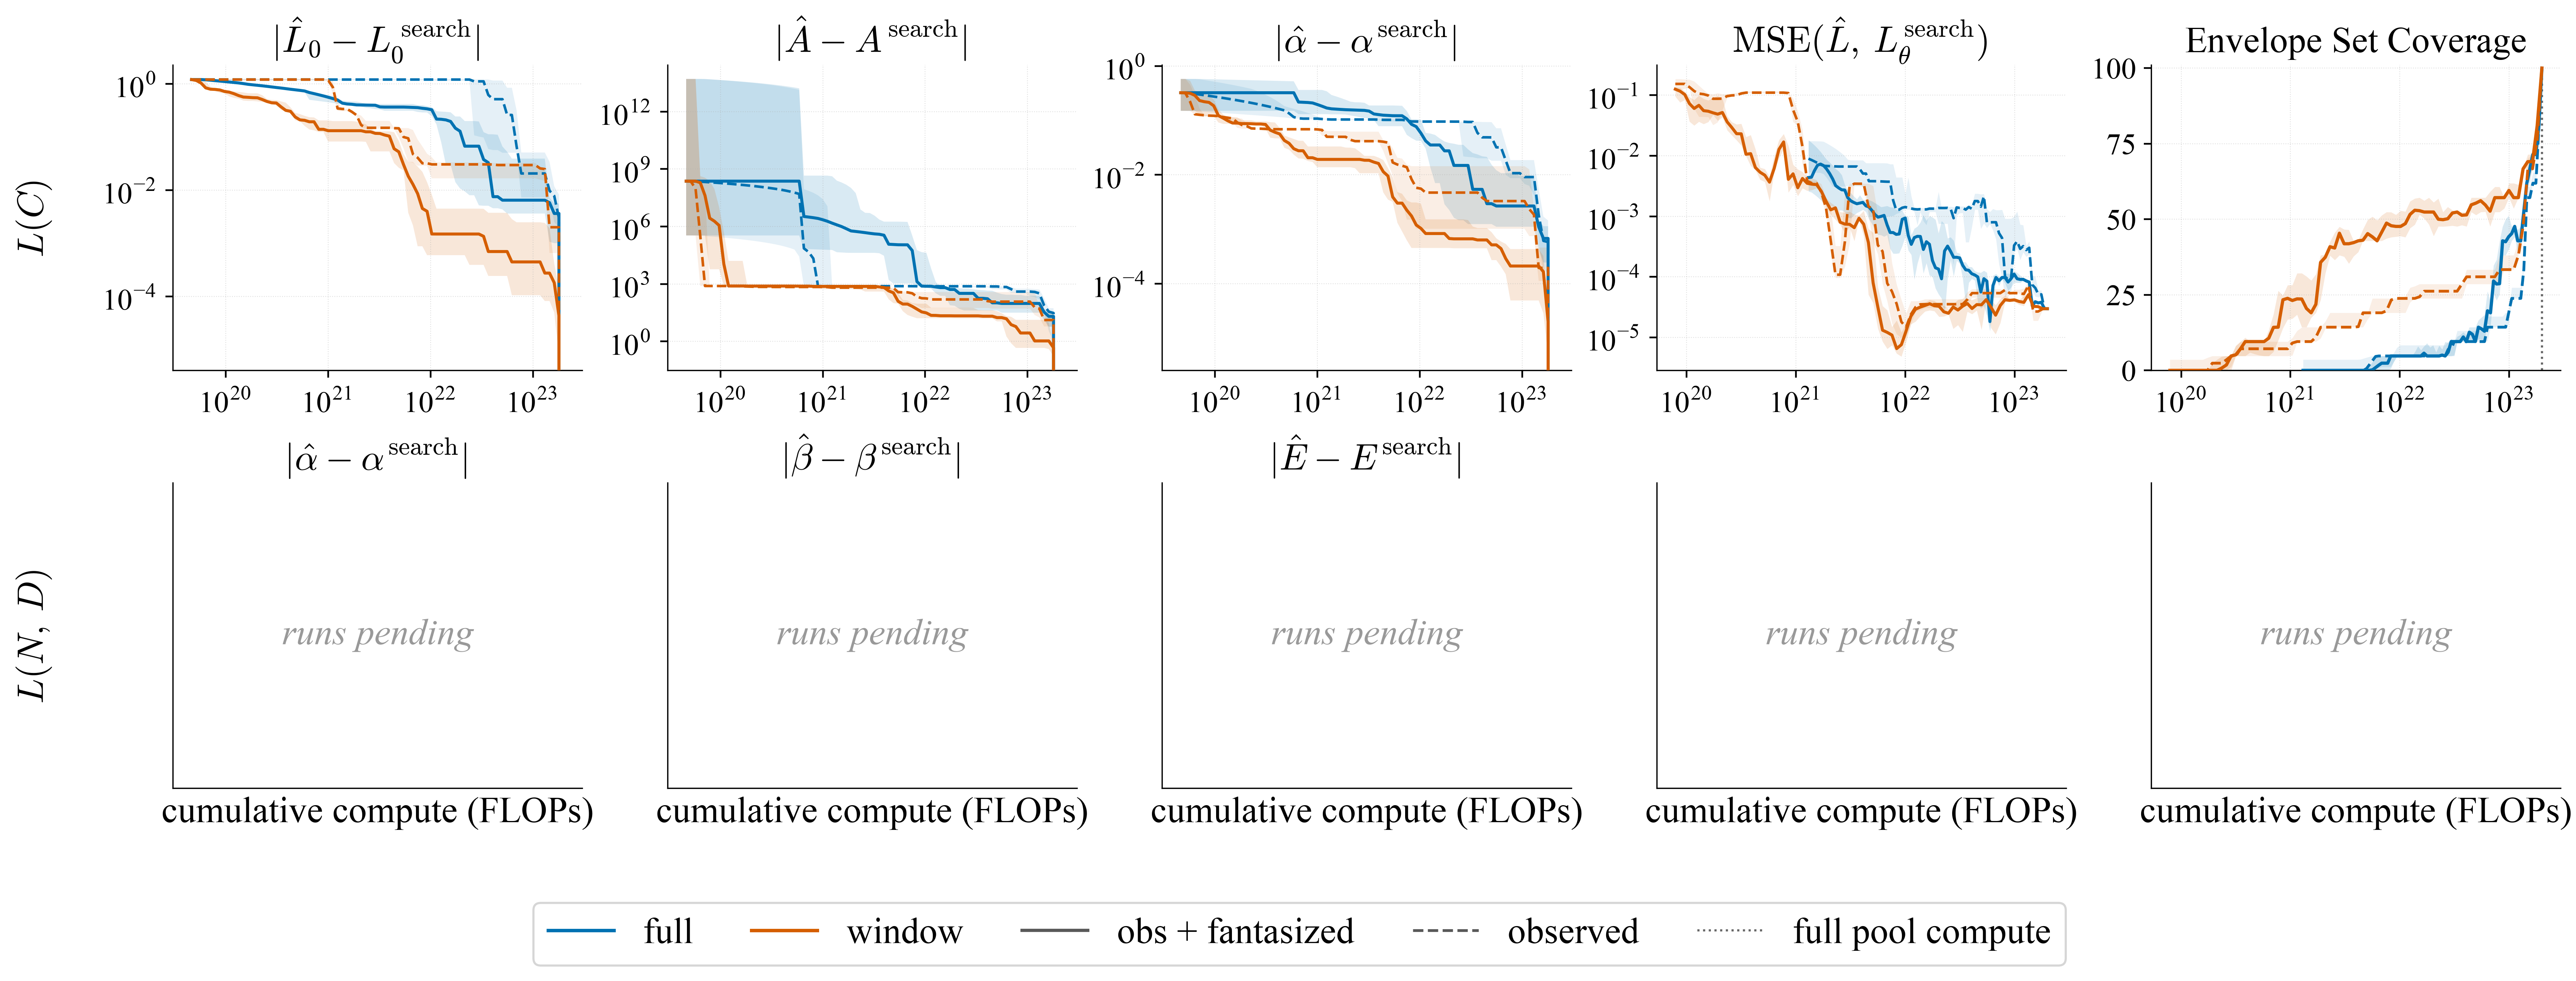

In [6]:
def regret_anchor(prep, name):
    return [(prep["init_info"][s]["compute"], abs(prep["init_info"][s]["interp"][name] - prep["val_ref"][name]))
            for s in prep["seeds"]]

def plot_row(axes_row, name, prep, show_mse_env_titles, show_xlabel):
    cfg = FORMS[name]
    coef_axes, ax_mse, ax_env = axes_row[:COEF_COLS], axes_row[-2], axes_row[-1]

    if prep is None:                                     # placeholder row
        for ax, cn in zip(coef_axes, cfg["params"]): ax.set_title(PLABEL[cn])
        if show_mse_env_titles: ax_mse.set_title(MSE_LABEL); ax_env.set_title(ENV_LABEL)
        for ax in axes_row:
            ax.text(0.5, 0.5, "runs pending", transform=ax.transAxes, ha="center", va="center",
                    color="0.6", style="italic")
            ax.set_xticks([]); ax.set_yticks([])
            if show_xlabel: ax.set_xlabel("cumulative compute (FLOPs)")
        return

    seeds, A, pool = prep["seeds"], prep["arms"], prep["pool"]
    # coefficient recovery: obs+fantasized (solid) vs observed-only (dashed)
    for ax, cn in zip(coef_axes, cfg["params"]):
        anc = regret_anchor(prep, cn)
        for a, ac in A.items():
            C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], f"regret_val_{cn}",
                                            anchors=anc, abs_first=True)
            ax.plot(C, med, color=ac["color"], lw=1.4, ls="-", zorder=3)
            ax.fill_between(C, lo, hi, color=ac["color"], alpha=0.15, lw=0)
            C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], f"regret_obs_only_val_{cn}",
                                            anchors=anc, abs_first=True)
            ax.plot(C, med, color=ac["color"], lw=1.2, ls="--", zorder=3)
            ax.fill_between(C, lo, hi, color=ac["color"], alpha=0.10, lw=0)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(PLABEL[cn])

    # held-out frontier MSE: obs+fantasized (solid, logged) vs observed-only (dashed, recomputed)
    for a, ac in A.items():
        C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], "law_mse_held_out", running=False)
        ax_mse.plot(C, med, color=ac["color"], lw=1.4, ls="-", zorder=3)
        ax_mse.fill_between(C, lo, hi, color=ac["color"], alpha=0.15, lw=0)
        C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], "law_mse_obs_only_held_out", running=False)
        ax_mse.plot(C, med, color=ac["color"], lw=1.2, ls="--", zorder=3)
        ax_mse.fill_between(C, lo, hi, color=ac["color"], alpha=0.10, lw=0)
    ax_mse.set_xscale("log"); ax_mse.set_yscale("log")
    if show_mse_env_titles: ax_mse.set_title(MSE_LABEL)

    # envelope-set coverage: obs+fantasized (solid) vs observed (dashed)
    for a, ac in A.items():
        g, med, q1, q3 = agg_recovery([fantasized_recovery(Path(prep["hist"][a][s].attrs["run_dir"]),
                                                            prep["hist"][a][s], pool) for s in seeds])
        ax_env.plot(g, med, color=ac["color"], lw=1.5, ls="-", zorder=3)
        ax_env.fill_between(g, q1, q3, color=ac["color"], alpha=0.15, lw=0)
        g, med, q1, q3 = agg_recovery([observed_recovery(prep["hist"][a][s], pool) for s in seeds])
        ax_env.plot(g, med, color=ac["color"], lw=1.3, ls="--", zorder=3)
        ax_env.fill_between(g, q1, q3, color=ac["color"], alpha=0.10, lw=0)
    ax_env.axvline(pool["pool_total_C"], color="0.4", ls=":", lw=1.0, zorder=2)
    ax_env.set_xscale("log"); ax_env.set_ylim(0, 101)
    if show_mse_env_titles: ax_env.set_title(ENV_LABEL)

    for ax in axes_row:
        if show_xlabel: ax.set_xlabel("cumulative compute (FLOPs)")
        ax.grid(which="major", ls=":", lw=0.4, alpha=0.4)

# shared full/window/style legend proxies (also used by the standalone L(C) figure below)
LEGEND_HANDLES = [Line2D([], [], color=BLUE, lw=1.6, label="full"),
                  Line2D([], [], color=VERM, lw=1.6, label="window"),
                  Line2D([], [], color="0.35", lw=1.5, ls="-",  label="obs + fantasized"),
                  Line2D([], [], color="0.35", lw=1.3, ls="--", label="observed"),
                  Line2D([], [], color="0.4",  lw=1.0, ls=":",  label="full pool compute")]

nrows, ncols = len(FORMS), COEF_COLS + 2
fig, axes = plt.subplots(nrows, ncols, figsize=(PANEL_W * ncols, PANEL_H * nrows))
axes = np.atleast_2d(axes)
for i, (name, cfg) in enumerate(FORMS.items()):
    plot_row(axes[i], name, PREP[name], show_mse_env_titles=(i == 0), show_xlabel=(i == nrows - 1))
    axes[i][0].annotate(cfg["title"], xy=(-0.34, 0.5), xycoords="axes fraction",
                        rotation=90, va="center", ha="center", fontsize=17)

# one shared horizontal legend below the grid (explicit proxies so it is drawn even for placeholder rows)
fig.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
           ncol=len(LEGEND_HANDLES), frameon=True, bbox_to_anchor=(0.5, -0.06),
           handlelength=1.8, columnspacing=1.6)
fig.tight_layout(pad=0.4, rect=(0, 0.09, 1, 1))
fig.savefig(OUT_DIR / "fig_recovery_grid.pdf")
plt.show()

## 6 · L(C) row on its own

The same strip for `L(C)` alone (form `L0`), for slides/paper where only the compute-law row is shown.
Reuses `plot_row`; saves `out/fig_recovery_LC.pdf`.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


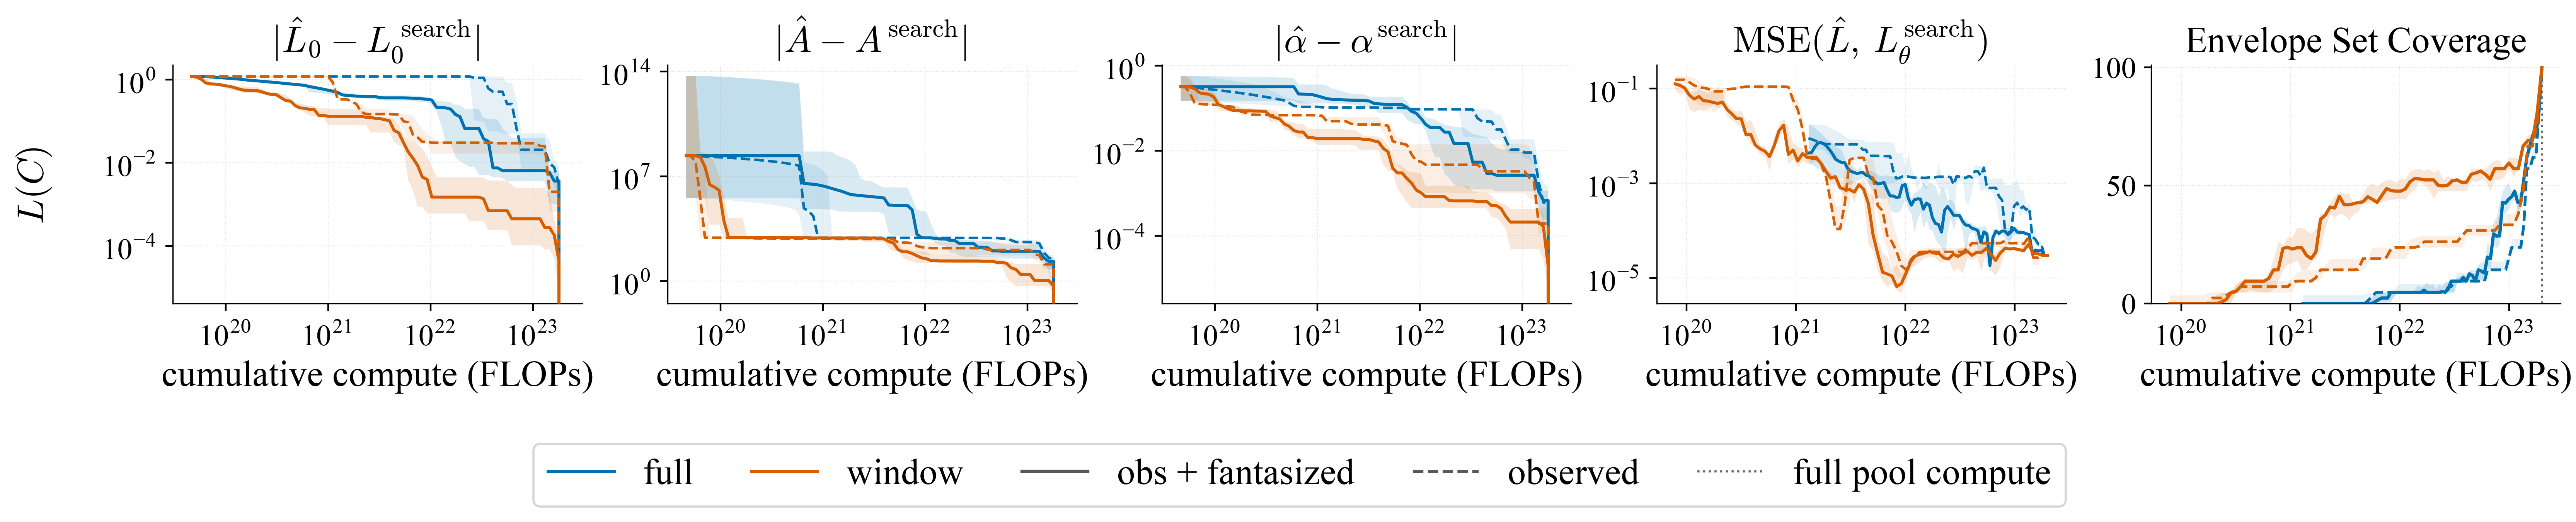

In [7]:
name = "L(C)"
ncols = COEF_COLS + 2
figc, axc = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))
plot_row(axc, name, PREP[name], show_mse_env_titles=True, show_xlabel=True)
axc[0].annotate(FORMS[name]["title"], xy=(-0.34, 0.5), xycoords="axes fraction",
                rotation=90, va="center", ha="center", fontsize=17)
figc.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
            ncol=len(LEGEND_HANDLES), frameon=True, bbox_to_anchor=(0.5, -0.13),
            handlelength=1.8, columnspacing=1.6)
figc.tight_layout(pad=0.4, rect=(0, 0.12, 1, 1))
figc.savefig(OUT_DIR / "fig_recovery_LC.pdf")
plt.show()